In [69]:
# -------------------------------------------
# 1. Load the event data for the top 5 Leagues
# -------------------------------------------
from pathlib import Path
import pandas as pd

leagues = ["bundesliga", 
           "la-liga",
           "ligue1",
           "prem",
           "serie-a"]
league_dfs = []

for league in leagues:
    league_events = pd.read_csv(Path.cwd().parent /f"data/raw/{league}-event-data-25-26.csv")

    league_events["league"] = league

    league_dfs.append(league_events)

# Concat the data into one df
events = pd.concat(league_dfs, ignore_index = True)

In [89]:
# -------------------------------------------
# 2. Filter for passes
# -------------------------------------------
passes_df = events[events["type"] == "Pass"]

In [91]:
# -------------------------------------------
# 3. Extract length and angle for qualifiers
# -------------------------------------------
import ast

def extract_pass_metrics(qualifiers):

    if isinstance(qualifiers, str):
        try:
            qualifiers = ast.literal_eval(qualifiers)
        except (ValueError, SyntaxError):
            return {}

    extracted = {}

    if not isinstance(qualifiers, list):
        return extracted

    for qualifier in qualifiers:
        if not isinstance(qualifier, dict):
            continue

        name = qualifier.get("type", {}).get("displayName")

        if name in ["Length", "Angle"]:
            extracted[name] = qualifier.get("value")

    return extracted


qualifier_data = passes_df["qualifiers"].apply(extract_pass_metrics)

qualifier_df = pd.DataFrame(
    qualifier_data.tolist(),
    index=passes_df.index
)

passes_df = pd.concat(
    [passes_df, qualifier_df],
    axis=1
)

passes_df[["Length", "Angle"]] = passes_df[["Length", "Angle"]].apply(
    pd.to_numeric, errors="coerce"
)

In [101]:
# -------------------------------------------
# 4. Convert outcomes to binary
# -------------------------------------------
passes_df["completed"] = (passes_df["outcome_type"] == "Successful").astype(int)

print(passes_df["completed"].value_counts())

completed
1    1369438
0     319567
Name: count, dtype: int64


In [117]:
# -------------------------------------------
# 5. Convert angles
# -------------------------------------------
import numpy as np

# Transform angle into sine and cosine
passes_df["angle_sin"] = np.sin(passes_df["Angle"])
passes_df["angle_cos"] = np.cos(passes_df["Angle"])


In [119]:
# -------------------------------------------
# 6. Define training and target features
# -------------------------------------------
features = ["x",
            "y",
            "end_x",
            "end_y",
            "Length",
            "angle_sin",
            "angle_cos"]

X = passes_df[features].copy()
y = passes_df["completed"].copy()
groups = passes_df["game_id"].copy()

print("Missing features:", X.isna().sum().sum())
print("Missing targets:", y.isna().sum())
print("Unique matches:", groups.nunique())
print("Total passes:", len(X))

Missing features: 0
Missing targets: 0
Unique matches: 1752
Total passes: 1689005


In [121]:
# -------------------------------------------
# 7. Split test and train data
# -------------------------------------------
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits = 1,
                             test_size = 0.2,
                             random_state = 42)

train_idx, test_idx = next(splitter.split(X,
                                          y,
                                          groups = groups))
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training passes:", len(X_train))
print("Testing passes:", len(X_test))

print("Training matches:", groups.iloc[train_idx].nunique())
print("Testing matches:", groups.iloc[test_idx].nunique())

Training passes: 1348272
Testing passes: 340733
Training matches: 1401
Testing matches: 351


In [131]:
# -------------------------------------------
# 8. Train a logistic regression model
# -------------------------------------------
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

LR_model = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter = 1000))

LR_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

In [133]:
# -------------------------------------------
# 9. Evaluate the Logistic Regression
# -------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

y_pred_proba = LR_model.predict_proba(X_test)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"Log Loss:  {log_loss(y_test, y_pred_proba):.4f}")
print(f"Brier:     {brier_score_loss(y_test, y_pred_proba):.4f}")

Accuracy:  0.8290
ROC-AUC:   0.8054
Log Loss:  0.3846
Brier:     0.1215


In [149]:
# -------------------------------------------
# 9. Save LR xPass values
# -------------------------------------------
passes_df["xPass_LR"] = LR_model.predict_proba(X)[:, 1]

In [151]:
# -------------------------------------------
# 10. Compare to a basline model
# -------------------------------------------

print(y_test.value_counts(normalize=True) * 100)

completed
1    81.346978
0    18.653022
Name: proportion, dtype: float64


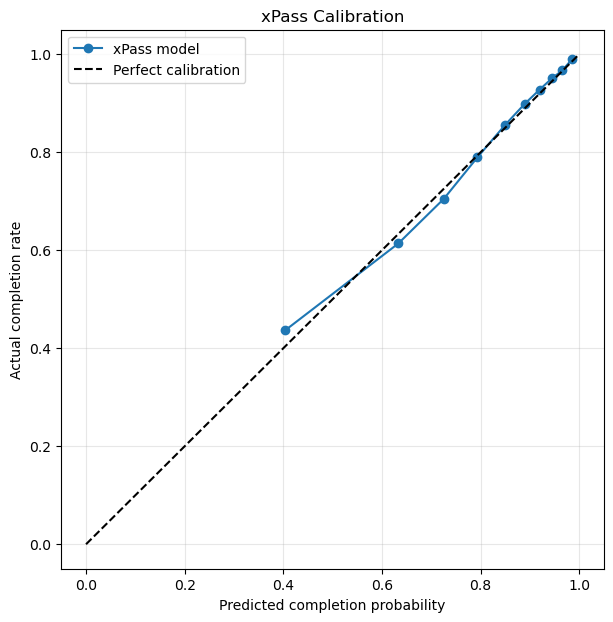

,mean_predicted,actual_completion,pass_count,difference
probability_bin,,,,
"(0.028399999999999998, 0.559]",0.403478,0.436315,34074,0.032837
"(0.559, 0.687]",0.633150,0.613770,34073,-0.019380
"(0.687, 0.761]",0.725402,0.704898,34073,-0.020504
"(0.761, 0.824]",0.793611,0.789599,34073,-0.004012
"(0.824, 0.872]",0.849652,0.855696,34074,0.006045
"(0.872, 0.906]",0.889883,0.899187,34073,0.009304
"(0.906, 0.933]",0.919852,0.927919,34073,0.008067
"(0.933, 0.956]",0.944735,0.950929,34073,0.006194
"(0.956, 0.975]",0.965636,0.966924,34073,0.001288


In [153]:
# -------------------------------------------
# 10. Check Calibration
# -------------------------------------------
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    y_pred_proba,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(prob_pred, prob_true, marker="o", label="xPass model")
ax.plot([0, 1], [0, 1], linestyle="--", color="black", label="Perfect calibration")

ax.set_xlabel("Predicted completion probability")
ax.set_ylabel("Actual completion rate")
ax.set_title("xPass Calibration")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

calibration_df = pd.DataFrame({
    "predicted": y_pred_proba,
    "actual": y_test.values
})

calibration_df["probability_bin"] = pd.qcut(
    calibration_df["predicted"],
    q=10,
    duplicates="drop"
)

calibration_summary = calibration_df.groupby(
    "probability_bin",
    observed=True
).agg(
    mean_predicted=("predicted", "mean"),
    actual_completion=("actual", "mean"),
    pass_count=("actual", "size")
)

calibration_summary["difference"] = (
    calibration_summary["actual_completion"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary)

In [196]:
# -------------------------------------------
# 11. Train a Gradient Boosting model
# -------------------------------------------
from sklearn.ensemble import HistGradientBoostingClassifier

GB_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)

GB_model.fit(X_train, y_train)

,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",15
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide `... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.",'from_dt

In [200]:
# -------------------------------------------
# 12. Evaluate the Gradient Boosting model
# -------------------------------------------
gb_proba = GB_model.predict_proba(X_test)[:, 1]
gb_pred = (gb_proba >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, gb_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, gb_proba):.4f}")
print(f"Log Loss:  {log_loss(y_test, gb_proba):.4f}")
print(f"Brier:     {brier_score_loss(y_test, gb_proba):.4f}")

Accuracy:  0.8848
ROC-AUC:   0.9115
Log Loss:  0.2747
Brier:     0.0840


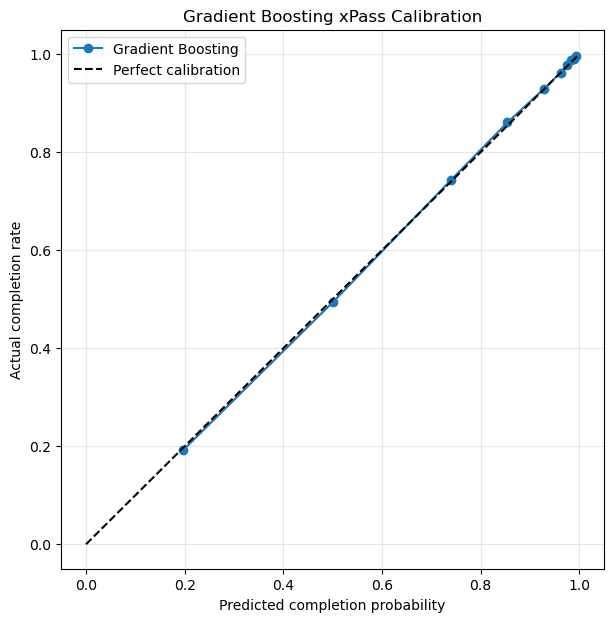

,mean_predicted,actual_completion,pass_count,difference
probability_bin,,,,
"(-0.000554, 0.33]",0.196398,0.191524,34074,-0.004873
"(0.33, 0.661]",0.500846,0.494409,34073,-0.006437
"(0.661, 0.804]",0.740587,0.743873,34073,0.003286
"(0.804, 0.9]",0.854412,0.860799,34073,0.006387
"(0.9, 0.95]",0.928697,0.929653,34074,0.000956
"(0.95, 0.971]",0.962045,0.962346,34073,0.000300
"(0.971, 0.98]",0.975785,0.978135,34073,0.002350
"(0.98, 0.986]",0.983552,0.987380,34073,0.003828
"(0.986, 0.991]",0.988734,0.990931,34073,0.002197


In [202]:
# -------------------------------------------
# 13. Check Calibration
# -------------------------------------------

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    gb_proba,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Gradient Boosting"
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    label="Perfect calibration"
)

ax.set_xlabel("Predicted completion probability")
ax.set_ylabel("Actual completion rate")
ax.set_title("Gradient Boosting xPass Calibration")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

calibration_gb_df = pd.DataFrame({
    "predicted": gb_proba,
    "actual": y_test.values
})

calibration_gb_df["probability_bin"] = pd.qcut(
    calibration_gb_df["predicted"],
    q=10,
    duplicates="drop"
)

calibration_summary = calibration_gb_df.groupby(
    "probability_bin",
    observed=True
).agg(
    mean_predicted=("predicted", "mean"),
    actual_completion=("actual", "mean"),
    pass_count=("actual", "size")
)

calibration_summary["difference"] = (
    calibration_summary["actual_completion"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary)

In [204]:
# -------------------------------------------
# 14. Save GB xPass values
# -------------------------------------------
passes_df["xPass_GB"] = GB_model.predict_proba(X)[:, 1]

### Passes Above Expected (PAx)
We can examine indivudal performances to see a players Passes above expected (PAx). Defined as the difference between actual passes completed and the predicted number of passes completed by the model. 

In [206]:
# -------------------------------------------
# 15. Passes Above Expcted 
# -------------------------------------------
passes_df["PAx_LR"] = (
    passes_df["completed"] - passes_df["xPass_LR"]
)

passes_df["PAx_GB"] = (
    passes_df["completed"] - passes_df["xPass_GB"]
)

def get_player_summary(player_name, match_id):
    player_passes = passes_df[
    (passes_df["player"] == player_name) &
    (passes_df["game_id"] == match_id)].copy()

    summary = pd.Series({
    "Passes attempted": len(player_passes),
    "Passes completed": player_passes["completed"].sum(),
    "Actual completion %": player_passes["completed"].mean() * 100,
    "Expected completions (LR)": player_passes["xPass_LR"].sum(),
    "Expected completions (GB)": player_passes["xPass_GB"].sum(),
    "PAx (LR)": player_passes["PAx_LR"].sum(),
    "PAx (GB)": player_passes["PAx_GB"].sum()})

    display(summary)

In [208]:
get_player_summary(player_name = "Elliot Anderson",
                   match_id = 1903329)

Passes attempted             103.000000
Passes completed              80.000000
Actual completion %           77.669903
Expected completions (LR)     74.852600
Expected completions (GB)     79.435389
PAx (LR)                       5.147400
PAx (GB)                       0.564611
dtype: float64

In [210]:
get_player_summary(player_name = "Andrey Santos",
                   match_id = 1903449)

Passes attempted              38.000000
Passes completed              38.000000
Actual completion %          100.000000
Expected completions (LR)     33.307964
Expected completions (GB)     34.389126
PAx (LR)                       4.692036
PAx (GB)                       3.610874
dtype: float64

In [212]:
get_player_summary(player_name = "Bruno Fernandes",
                   match_id = 1903431)

Passes attempted             68.000000
Passes completed             56.000000
Actual completion %          82.352941
Expected completions (LR)    49.788872
Expected completions (GB)    51.189605
PAx (LR)                      6.211128
PAx (GB)                      4.810395
dtype: float64

In [228]:
get_player_summary(player_name = "Hugo Ekitiké",
                  match_id = 1903462)

Passes attempted               2.000000
Passes completed               2.000000
Actual completion %          100.000000
Expected completions (LR)      1.758026
Expected completions (GB)      1.818867
PAx (LR)                       0.241974
PAx (GB)                       0.181133
dtype: float64